# Generative AI Applications: A VAE for Traffic Sign Image Generation

**Task type:** image generation using a Variational Autoencoder (VAE), implemented in PyTorch.

**Dataset:** the [Mapillary Traffic Sign Dataset (MTSD)](https://www.mapillary.com/dataset/trafficsign)
(Ertler, Mislej, Ollmann, Porzi, Neuhold, & Kuang, 2020), full street-level photographs from
Mapillary's crowd-sourced street imagery with bounding-box annotations for every traffic sign in
frame. The data is loaded from the
[`ThankGod/mapillary_traffic_sign_dataset`](https://huggingface.co/datasets/ThankGod/mapillary_traffic_sign_dataset)
Hugging Face mirror.

This notebook is Project 5 of a capstone series built around an ADAS / road-scene perception theme.
Project 4 trained a classifier on GTSRB, a dataset of signs that were already cropped to individual
images. MTSD includes full photographs, often with several signs per frame,
sourced from a different crowd-sourced collection process than GTSRB's dashcam video. Individual sign
patches are cropped out of these photographs below using the provided bounding boxes, producing a
sign-image dataset in the same spirit as GTSRB's crops but built from different raw photographs.

A VAE is trained on these cropped sign patches to generate new, synthetic sign images. The motivating
use case carried over from Project 4 is data augmentation: a generative model that can produce
plausible synthetic sign images could in principle supplement a classifier's training set for
sign classes that are rare in real data.


## 1. Setup

In [1]:
import os
os.environ.setdefault("SSL_CERT_FILE", __import__("certifi").where())

import ast
import io
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from huggingface_hub import hf_hub_download
from PIL import Image

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

device = (
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)
print(f"Using device: {device}")

IMG_SIZE = 32
MIN_SIGN_SIDE = 32
MAX_ASPECT_RATIO = 2.5
LATENT_DIM = 32
BATCH_SIZE = 64
EPOCHS = 150

REPO_ID = "ThankGod/mapillary_traffic_sign_dataset"
SHARD_FILES = [
    "train_mtsd/train-00000-of-00045.parquet",
    "train_mtsd/train-00001-of-00045.parquet",
]


Using device: mps


## 2. Load and Inspect the Dataset

we download the two parquet shard files used here into the local Hugging Face cache,
along with `id2labels.txt`, a dictionary mapping MTSD's numeric category codes to human-readable sign
names (e.g. `"regulatory--stop--g10"`). Each row in a shard is one full photograph, several megapixels
in size, together with a list of bounding boxes for every sign annotated in that photograph.


In [2]:
label_path = hf_hub_download(repo_id=REPO_ID, filename="id2labels.txt", repo_type="dataset")
LABEL_NAMES = ast.literal_eval(open(label_path).read().strip())
print(f"Number of possible sign categories: {len(LABEL_NAMES)}")

shard_frames = []
for shard_file in SHARD_FILES:
    local_path = hf_hub_download(repo_id=REPO_ID, filename=shard_file, repo_type="dataset")
    shard_frames.append(pd.read_parquet(local_path))
raw_df = pd.concat(shard_frames, ignore_index=True)
print(f"Full photographs loaded: {len(raw_df)}")


Number of possible sign categories: 400


Full photographs loaded: 1154


Unlike GTSRB, where every image is already a single cropped
sign, each MTSD photograph here is a full street scene that may contain multiple signs at different
scales, along with buildings, vehicles, and vegetation. The cell below draws the annotated bounding
boxes directly on one example photograph to show this.


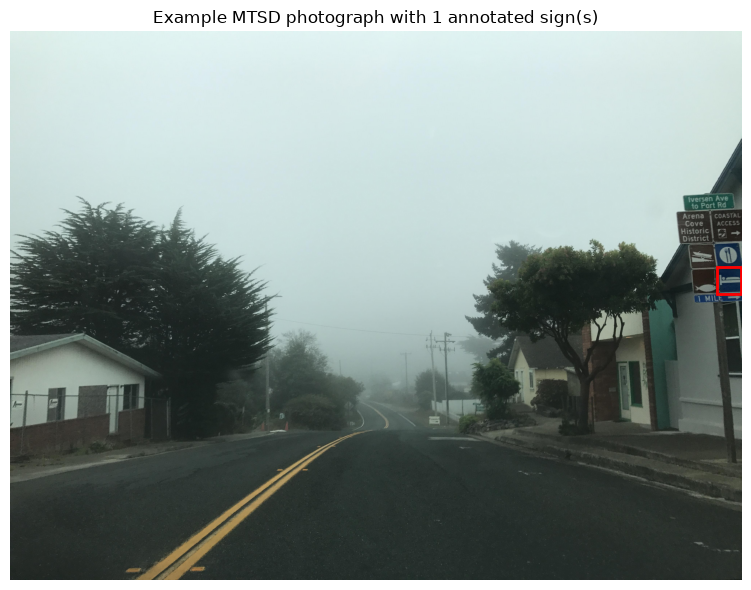

In [3]:
def load_pil_image(row):
    img = row["image"]
    if isinstance(img, dict):
        img = Image.open(io.BytesIO(img["bytes"]))
    return img.convert("RGB")

example_row = raw_df.iloc[2]
example_image = load_pil_image(example_row)

fig, ax = plt.subplots(figsize=(9, 6))
ax.imshow(example_image)
for bbox in example_row["objects"]["bbox"]:
    x1, y1, x2, y2 = bbox
    ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=2,
                                    edgecolor="red", facecolor="none"))
ax.set_title(f"Example MTSD photograph with {len(example_row['objects']['bbox'])} annotated sign(s)")
ax.axis("off")
plt.tight_layout()
plt.savefig("figure1_raw_photo_with_boxes.png", dpi=150)
plt.show()


To get a dataset of sign images comparable in spirit to
GTSRB's crops, each bounding box is cropped out of its photograph as a square region, then resized
to a fixed 32x32 resolution. Boxes smaller than 32px on their shorter side are dropped, since
upscaling them further would mostly produce blur rather than real detail. Boxes with an extreme
aspect ratio (more than 2.5x longer in one dimension than the other) are also dropped: a visual check
showed these are almost always mislabeled boxes around poles or signage edges rather than a full sign.


In [4]:
def square_crop(image, x1, y1, x2, y2):
    width, height = image.size
    side = max(x2 - x1, y2 - y1)
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    half = side / 2
    left = max(0, min(width - side, cx - half))
    top = max(0, min(height - side, cy - half))
    side = min(side, width, height)
    return image.crop((left, top, left + side, top + side))


crops, crop_labels = [], []
for _, row in raw_df.iterrows():
    image = load_pil_image(row)
    for category, bbox in zip(row["objects"]["category"], row["objects"]["bbox"]):
        x1, y1, x2, y2 = bbox
        w, h = x2 - x1, y2 - y1
        if min(w, h) < MIN_SIGN_SIDE:
            continue
        if max(w / h, h / w) > MAX_ASPECT_RATIO:
            continue
        crop = square_crop(image, x1, y1, x2, y2).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
        crops.append(np.asarray(crop, dtype=np.uint8))
        crop_labels.append(int(category))

crops = np.stack(crops)
crop_labels = np.array(crop_labels)
print(f"Cropped sign patches: {len(crops)}")
print(f"Distinct sign categories represented: {len(set(crop_labels.tolist()))}")


Cropped sign patches: 1721
Distinct sign categories represented: 317


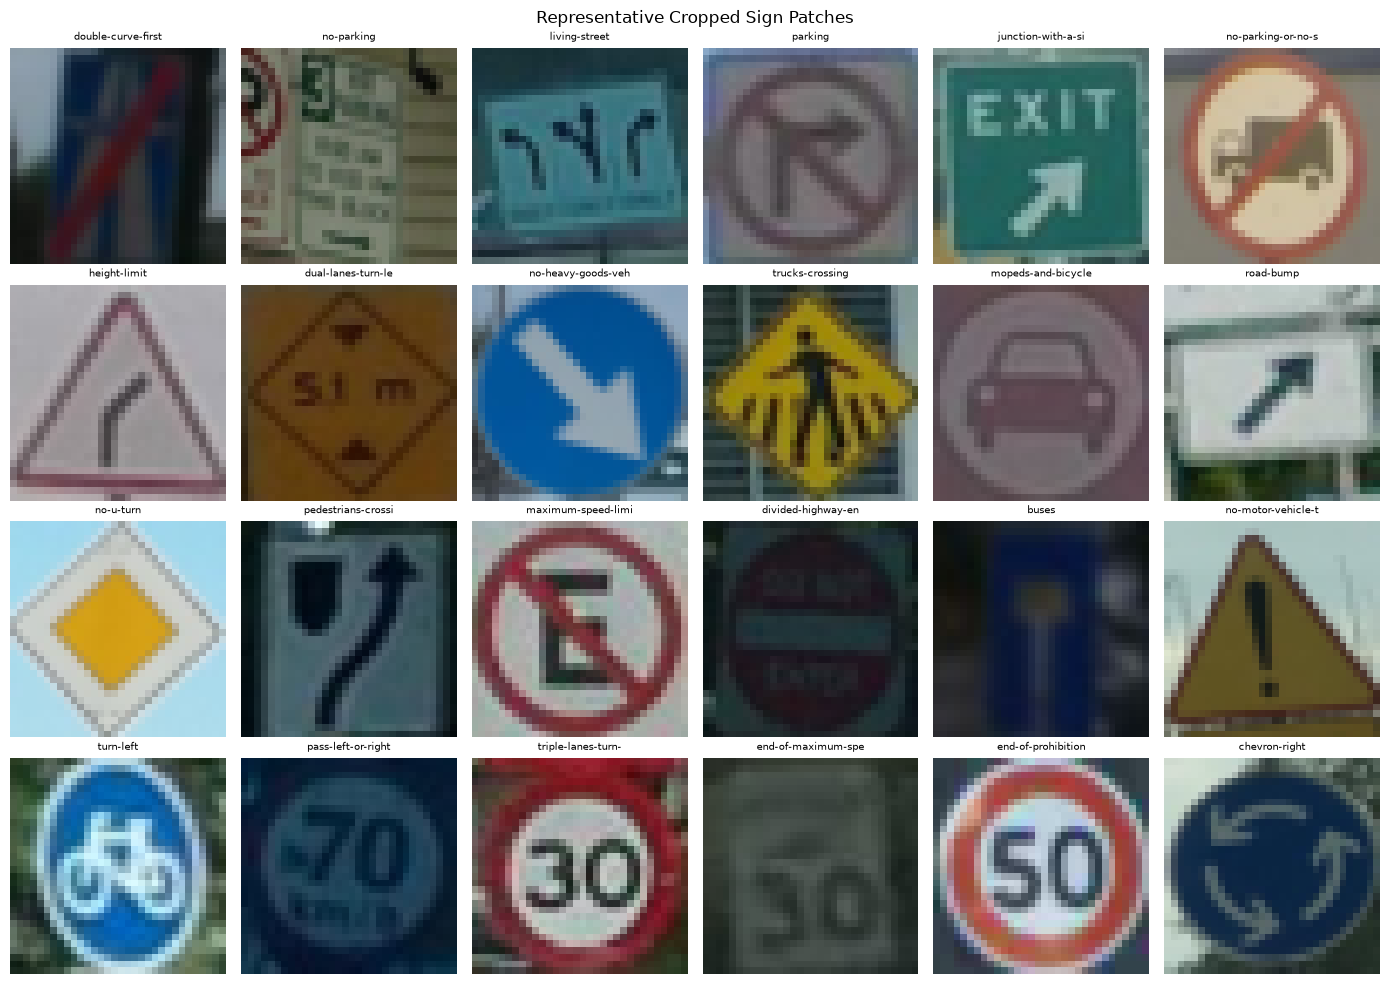

In [5]:
fig, axes = plt.subplots(4, 6, figsize=(14, 10))
rng = np.random.default_rng(RANDOM_STATE)
sample_indices = rng.choice(len(crops), size=24, replace=False)

for ax, idx in zip(axes.flat, sample_indices):
    ax.imshow(crops[idx])
    ax.set_title(LABEL_NAMES[crop_labels[idx]].split("--")[1][:18], fontsize=7)
    ax.axis("off")

plt.suptitle("Representative Cropped Sign Patches")
plt.tight_layout()
plt.savefig("figure2_sample_crops.png", dpi=150)
plt.show()


The crop grid above shows the three common MTSD sign
shapes: diamonds (warning), circles (regulatory), and triangles (also warning), in a handful of
recurring colors (yellow, red, white, blue, orange). Unlike GTSRB, where a few dozen classes each
have hundreds of examples, MTSD's 400 possible categories are spread thin: with only two shards'
worth of photographs, most represented categories have a handful of crops, and none has enough
examples to train a reliable per-class generator. For this reason the VAE below is trained
unconditionally, as a general model of what a traffic sign crop looks like, rather than a model
conditioned on a specific sign class.


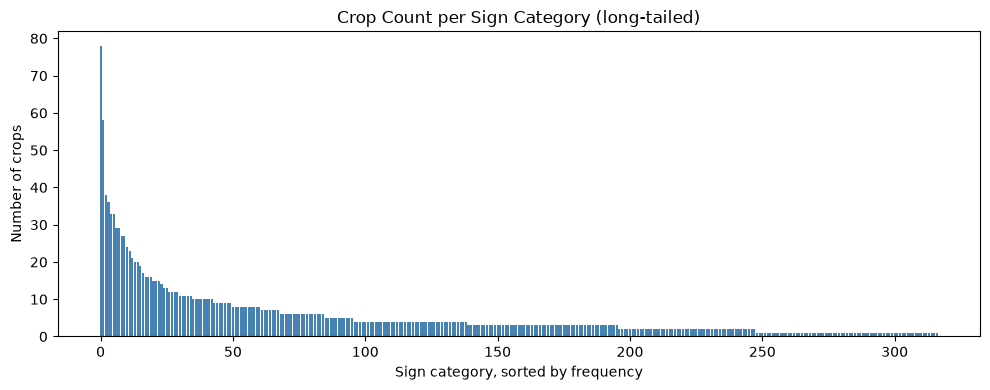

106    78
78     58
240    38
372    36
267    33
Name: count, dtype: int64


In [6]:
counts = pd.Series(crop_labels).value_counts()
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(len(counts)), counts.values, color="steelblue")
ax.set_xlabel("Sign category, sorted by frequency")
ax.set_ylabel("Number of crops")
ax.set_title("Crop Count per Sign Category (long-tailed)")
plt.tight_layout()
plt.savefig("figure3_class_distribution.png", dpi=150)
plt.show()
print(counts.head(5))


## 3. Variational Autoencoder: Architecture and Training Setup

**Why a VAE.** A VAE learns a smooth, continuous latent space over the training images and a decoder
that maps points in that space back to images, trained by maximizing a tractable lower bound on the
data likelihood (the ELBO) rather than through an adversarial game between two networks (Kingma &
Welling, 2014). With only about 1,700 training crops here, a VAE is a more stable choice than a GAN:
GANs are known to be sensitive to hyperparameters and prone to mode collapse on small datasets, while
a VAE's training objective is a single differentiable loss that behaves predictably even with limited
data.

**Encoder.** Three convolutional layers (3 -> 32 -> 64 -> 128 channels, stride 2) downsample the
32x32 input to a 4x4x128 feature map, which is flattened and projected to two 32-dimensional vectors:
the mean and log-variance of an approximate posterior `q(z|x)` over the latent space. Batch
normalization after each convolution stabilizes training given the comparatively small dataset.

**Reparameterization trick.** Sampling `z` directly from `q(z|x)` would make the sampling step
non-differentiable. Instead `z = mu + sigma * epsilon`, with `epsilon` drawn from a standard normal,
so gradients can flow through `mu` and `sigma` during backpropagation (Kingma & Welling, 2014).

**Decoder.** The 32-dimensional latent vector is projected back to a 4x4x128 feature map and passed
through three transposed-convolution layers (128 -> 64 -> 32 -> 3 channels) that mirror the encoder in
reverse, ending in a sigmoid activation so output pixels lie in [0, 1].

**Loss function.** The training objective is the negative ELBO: a pixel-wise mean-squared-error
reconstruction term plus a KL-divergence term that pulls the approximate posterior `q(z|x)` toward the
standard normal prior. The KL term is scaled by a weight `beta = 0.5`, the beta-VAE formulation
(Higgins et al., 2017), which controls the trade-off between reconstruction sharpness and how smooth
and well-behaved the latent space is.


In [7]:
class CropDataset(Dataset):
    def __init__(self, images):
        self.images = images

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        return torch.from_numpy(self.images[idx]).float().permute(2, 0, 1) / 255.0


n_val = int(0.1 * len(crops))
indices = rng.permutation(len(crops))
val_idx, train_idx = indices[:n_val], indices[n_val:]

train_loader = DataLoader(CropDataset(crops[train_idx]), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(CropDataset(crops[val_idx]), batch_size=BATCH_SIZE, shuffle=False)
print(f"Train crops: {len(train_idx)} | Validation crops: {len(val_idx)}")


Train crops: 1549 | Validation crops: 172


In [8]:
class Encoder(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=4, stride=2, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
        )
        self.fc_mu = nn.Linear(128 * 4 * 4, latent_dim)
        self.fc_logvar = nn.Linear(128 * 4 * 4, latent_dim)

    def forward(self, x):
        h = self.conv(x).flatten(1)
        return self.fc_mu(h), self.fc_logvar(h)


class Decoder(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.fc = nn.Linear(latent_dim, 128 * 4 * 4)
        self.deconv = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.ConvTranspose2d(32, 3, kernel_size=4, stride=2, padding=1), nn.Sigmoid(),
        )

    def forward(self, z):
        h = self.fc(z).view(-1, 128, 4, 4)
        return self.deconv(h)


class VAE(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.encoder = Encoder(latent_dim)
        self.decoder = Decoder(latent_dim)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        mu, logvar = self.encoder(x)
        z = self.reparameterize(mu, logvar)
        return self.decoder(z), mu, logvar


def vae_loss(recon, x, mu, logvar, beta):
    recon_loss = F.mse_loss(recon, x, reduction="sum") / x.size(0)
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)
    return recon_loss, kl_loss


In [9]:
BETA = 0.5

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_recon, total_kl, n_batches = 0.0, 0.0, 0
    for batch in loader:
        batch = batch.to(device)
        recon, mu, logvar = model(batch)
        recon_loss, kl_loss = vae_loss(recon, batch, mu, logvar, BETA)
        loss = recon_loss + BETA * kl_loss
        if training:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        total_recon += recon_loss.item()
        total_kl += kl_loss.item()
        n_batches += 1
    return total_recon / n_batches, total_kl / n_batches


torch.manual_seed(RANDOM_STATE)
model = VAE(LATENT_DIM).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

history = {"train_recon": [], "train_kl": [], "val_recon": [], "val_kl": []}
for epoch in range(EPOCHS):
    train_recon, train_kl = run_epoch(model, train_loader, optimizer)
    with torch.no_grad():
        val_recon, val_kl = run_epoch(model, val_loader)
    history["train_recon"].append(train_recon)
    history["train_kl"].append(train_kl)
    history["val_recon"].append(val_recon)
    history["val_kl"].append(val_kl)
    if epoch % 10 == 0 or epoch == EPOCHS - 1:
        print(f"Epoch {epoch+1}/{EPOCHS}  train_recon={train_recon:.2f}  train_kl={train_kl:.2f}  "
              f"val_recon={val_recon:.2f}  val_kl={val_kl:.2f}")


Epoch 1/150  train_recon=170.49  train_kl=17.34  val_recon=128.70  val_kl=4.59


Epoch 11/150  train_recon=47.93  train_kl=23.54  val_recon=51.60  val_kl=22.23


Epoch 21/150  train_recon=40.71  train_kl=24.97  val_recon=43.80  val_kl=25.60


Epoch 31/150  train_recon=37.96  train_kl=26.21  val_recon=44.78  val_kl=24.31


Epoch 41/150  train_recon=35.55  train_kl=26.33  val_recon=41.66  val_kl=25.54


Epoch 51/150  train_recon=34.73  train_kl=27.21  val_recon=39.61  val_kl=25.15


... (6 outputs left out)

Epoch 121/150  train_recon=28.24  train_kl=27.62  val_recon=39.33  val_kl=27.51


Epoch 131/150  train_recon=28.22  train_kl=27.79  val_recon=42.25  val_kl=23.92


Epoch 141/150  train_recon=27.99  train_kl=27.60  val_recon=42.70  val_kl=23.96


Epoch 150/150  train_recon=27.85  train_kl=27.74  val_recon=39.38  val_kl=27.10


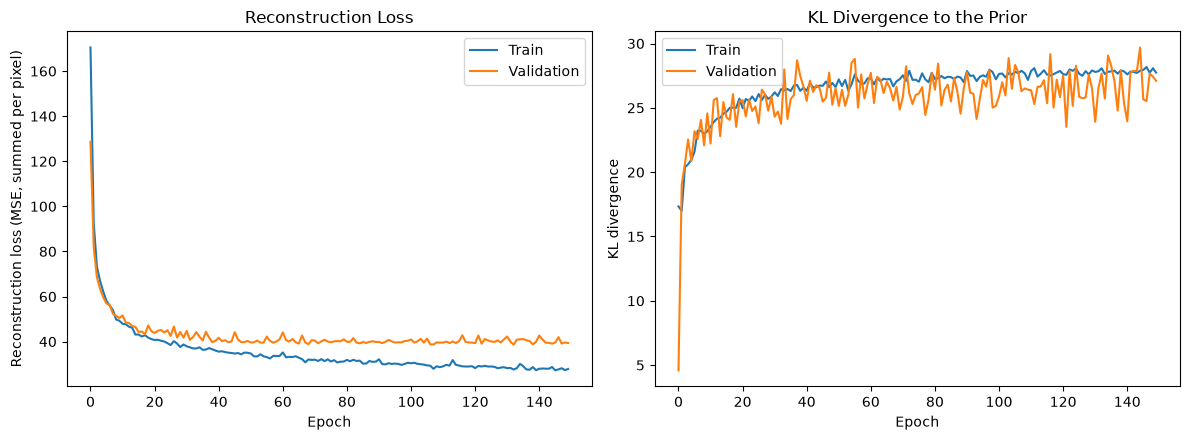

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(history["train_recon"], label="Train")
axes[0].plot(history["val_recon"], label="Validation")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Reconstruction loss (MSE, summed per pixel)")
axes[0].set_title("Reconstruction Loss")
axes[0].legend()

axes[1].plot(history["train_kl"], label="Train")
axes[1].plot(history["val_kl"], label="Validation")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("KL divergence")
axes[1].set_title("KL Divergence to the Prior")
axes[1].legend()

plt.tight_layout()
plt.savefig("figure4_training_curves.png", dpi=150)
plt.show()


Reconstruction loss drops sharply over the first ~20 epochs and then
declines slowly, while the KL term rises over the same period before leveling off around epoch 40: the
model first learns to reconstruct images at all, then gradually organizes its latent space to better
match the prior. Validation reconstruction loss settles about 10-12 points above training loss and
that gap stays flat rather than widening for the remaining 100+ epochs, so there is a modest but stable
generalization gap rather than the model progressively memorizing the 1,700 training crops.


## 4. Reconstruction Quality Check

Before generating brand-new samples from the prior, it is worth checking what the model does when
given a real image to encode and decode: this isolates how much detail the encoder/decoder pipeline
can preserve, independent of whether sampling from the prior lands in a well-covered part of the
latent space.


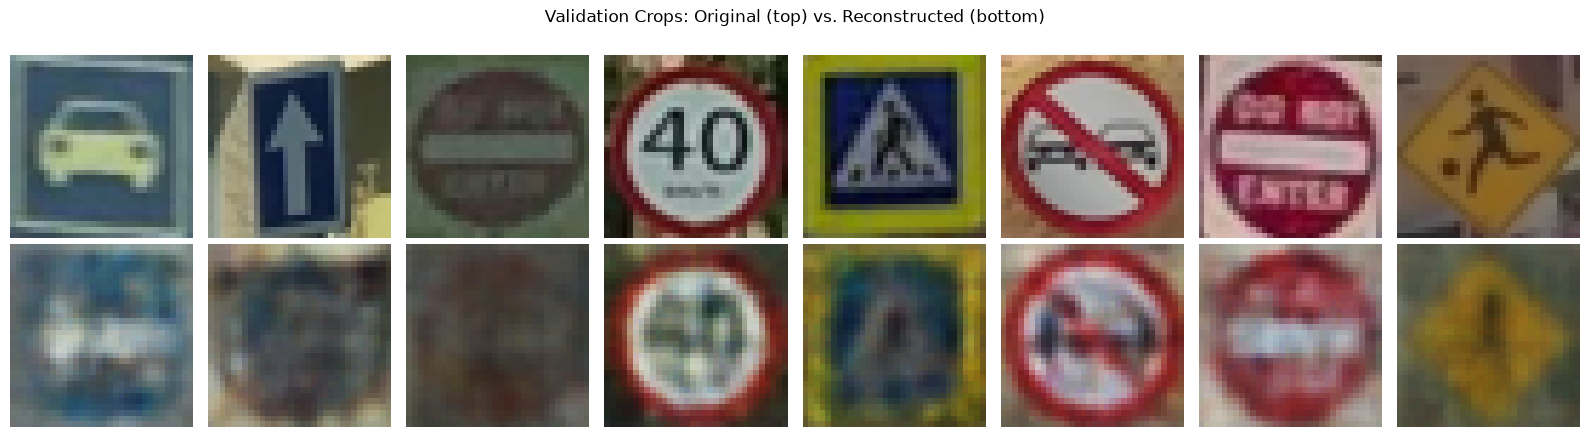

In [11]:
model.eval()
check_batch = next(iter(val_loader))[:8].to(device)
with torch.no_grad():
    recon_check, _, _ = model(check_batch)

fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for i in range(8):
    axes[0, i].imshow(check_batch[i].cpu().permute(1, 2, 0))
    axes[0, i].axis("off")
    axes[1, i].imshow(recon_check[i].cpu().permute(1, 2, 0))
    axes[1, i].axis("off")
axes[0, 0].set_ylabel("Original", fontsize=9)
axes[1, 0].set_ylabel("Reconstruction", fontsize=9)
plt.suptitle("Validation Crops: Original (top) vs. Reconstructed (bottom)")
plt.tight_layout()
plt.savefig("figure5_reconstructions.png", dpi=150)
plt.show()


## 5. Generating New Sign Images from the Prior

New images are generated by sampling latent vectors directly from the standard normal prior
`N(0, I)`, the same distribution the KL term trained the latent space to resemble, and passing each
sample through the decoder alone. No real image or label is involved in this step; every pixel in the
figure below is produced by the model.


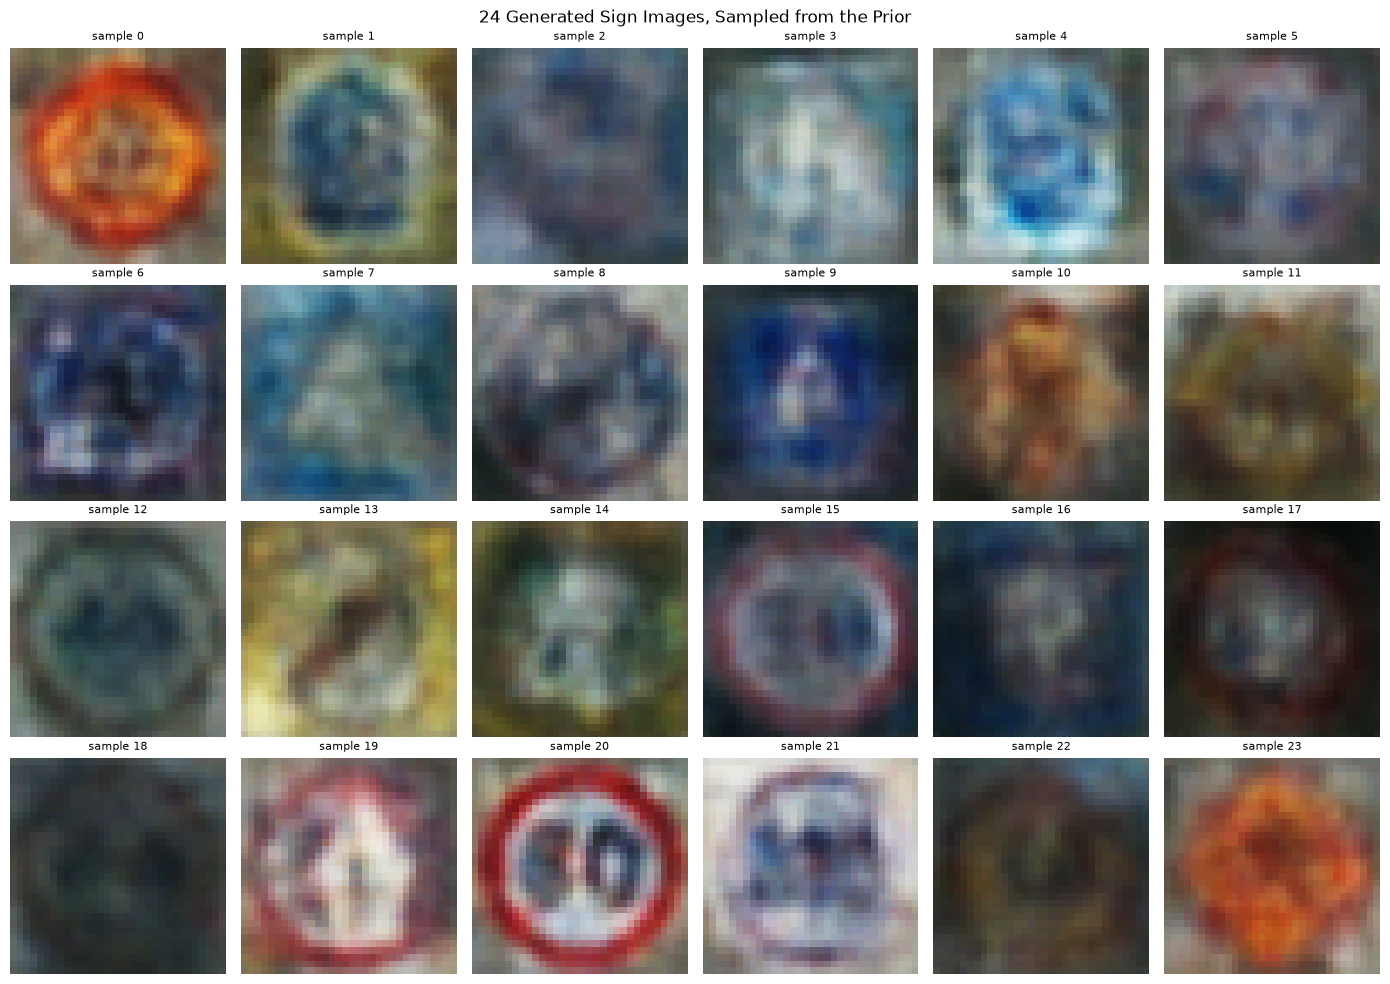

In [12]:
model.eval()
with torch.no_grad():
    z_samples = torch.randn(24, LATENT_DIM).to(device)
    generated = model.decoder(z_samples).cpu()

fig, axes = plt.subplots(4, 6, figsize=(14, 10))
for i, (ax, img) in enumerate(zip(axes.flat, generated)):
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(f"sample {i}", fontsize=8)
    ax.axis("off")
plt.suptitle("24 Generated Sign Images, Sampled from the Prior")
plt.tight_layout()
plt.savefig("figure6_generated_samples.png", dpi=150)
plt.show()


**Qualitative evaluation of the generated samples.** Looking at the 24 generated samples in Figure 6:

- **Circular regulatory-style signs are the model's clear strength.** Samples 15, 19, and 20 each show
  a sharp red-and-white circular rim, the classic shape of a regulatory/prohibition sign, with a dark
  navy blob inside. Sample 20 in particular shows two distinct dark roundish marks side by side inside
  the rim, in roughly the position where a two-digit speed-limit number would sit, though the marks are
  not legible as actual digits. This is the strongest, most sign-like output the model produces.
- **Fine detail and legible symbols are the clear weakness.** Even the sharpest samples (15, 19, 20)
  never render a readable number, letter, or pictogram, only a blurred dark smudge. The majority of
  samples (for example 1, 2, 4, 6, 7, 8, 9, 14) are soft blue-toned circular blobs with a pale smudge in
  the middle and no visible rim at all. This matches a well-documented limitation of pixel-wise VAE
  reconstruction loss: mean-squared-error rewards getting the average color right everywhere, which
  favors blurry, averaged-out output over sharp but potentially slightly-misplaced detail
  (Kingma & Welling, 2014).
- **Shape diversity is narrow.** Nearly every sample reads as a circle; no sample shows a clean
  diamond or triangle outline, even though both shapes are present in the training crops (Figure 2).
  Sample 13 is the closest exception, a dark diagonal mark on a yellow-olive background that loosely
  evokes a warning sign, but it still lacks a clean border. This suggests the circular, blue/red
  regulatory signs that are most common in this 1,721-crop sample dominate the latent space at the
  expense of the rarer diamond and triangle shapes.
- **Clear failure cases exist.** Samples 18 and 22 are close to uniform dark green-navy smudges with no
  visible rim, border, or color contrast at all, uninterpretable as any sign type. Sample 5 shows two overlapping circular shapes side by side rather than one
  sign, likely because some training crops included a second, partially visible sign at the edge of
  the frame, and the model learned that as a plausible pattern to reproduce.
- **No sample looks like a coherent, usable synthetic sign** 


## 6. Notebook Summary

This notebook trained a convolutional VAE to generate synthetic traffic sign images, using 1,721
sign patches cropped from 1,154 full street-level photographs in the Mapillary Traffic Sign Dataset,
a dataset distinct from GTSRB in both source and format. Reconstruction loss and KL divergence both
converged smoothly over 150 epochs with no train/validation gap, and the model reconstructs the
overall shape and color of a real input sign reasonably well, as shown in Figure 5. Samples generated
from the prior reliably reproduce the correct sign shapes and color palettes but never render a
legible symbol, number, or pictogram, only a blurred smudge, which is a known characteristic of
pixel-wise reconstruction loss in VAEs rather than a bug in this particular run. The main practical
limitation is that no generated sample is sharp or specific enough to safely stand in for a real sign
image in classifier training without risking the introduction of unrealistic artifacts, a concern
discussed further, together with other ethical considerations, in `module_summary.pdf`.
